# 09. PSI: неизвестные сдвиги и межкадровые наклоны

Курс «От интерференции до измерения поверхности». [Маршрут](README.md).

**Цели:** построить нелинейную задачу, понять чередование оценок, калибровочные свободы и variable projection.

Работайте сверху вниз, затем меняйте параметры и выполняйте **Restart Kernel → Run All**.
Все численные примеры учебные: они объясняют метод, а не подтверждают точность прибора.
Рекомендуемый темп: одна тетрадь за занятие, с собственными записями и упражнениями.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage, signal, interpolate, optimize

course_dir = next(p for p in [Path.cwd(), Path.cwd()/"notes"/"interferometry-course"]
                  if (p/"course_lib.py").exists())
if str(course_dir) not in sys.path:
    sys.path.insert(0, str(course_dir))
import course_lib as cl
np.set_printoptions(precision=5, suppress=True)

## 1. Что стало неизвестным

Теперь δₙ нужно найти из тех же изображений. Полная задача:
$$\min_{a_p,b_p,\varphi_p,\delta_n}\sum_{n,p}
[I_{np}-a_p-b_p\cos(\varphi_p+\delta_n)]^2.$$
Индекс p обозначает пиксель. Есть калибровочная свобода:
$\varphi_p\to\varphi_p+\alpha$, $\delta_n\to\delta_n-\alpha$.
Фиксируем δ₀=0. Остаётся дискретная неоднозначность
$(\varphi,\delta)\to(-\varphi,-\delta)$. Номинальные сдвиги выбирают ветвь только
при обоснованном знании направления движения фазосдвигателя.

Малое изменение параметров на последней итерации означает остановку процесса,
а не попадание в правильный минимум. Проверять надо также интенсивностную невязку,
ошибку на синтетической правде, устойчивость к старту и к модели освещения.

In [2]:
s=cl.scene(n=64,carrier_x=6,carrier_y=2,bowl=.3)
true_shifts=np.deg2rad([0,75,170,260,345])
nominal=np.arange(5)*np.pi/2
a=.5+.08*np.cos(s['phi'])  # специально коррелированный с фазой фон
b=np.full_like(a,.25)
stack=np.array([a+b*np.cos(s['phi']+d) for d in true_shifts])
print('Диапазон яркостей:',stack.min(),stack.max())

Диапазон яркостей: 0.1700000041350568 0.829999957657019


## 2. Почему «поменять местами кадры и пиксели» недостаточно

При фиксированной φ удобно написать по пикселям
$I_{np}=a_p+b_p\cos\varphi_p\cos\delta_n-b_p\sin\varphi_p\sin\delta_n$.
Но если регрессировать сырые I на $[1,\cos\varphi,-\sin\varphi]$ с **одним**
набором коэффициентов для всего поля, пространственные aₚ,bₚ подменяются
глобальными числами. Такая подгонка не эквивалентна общей модели.

При постоянном фоне/амплитуде она работает хорошо. При меняющемся фоне смещается.
Ни увеличение числа точек, ни ранняя остановка не устраняют ошибку постановки.
Следующий пример использует даже истинную φ: ошибка появляется до развёртки.

In [3]:
D=np.column_stack([np.ones(s['mask'].sum()),np.cos(s['phi'][s['mask']]),-np.sin(s['phi'][s['mask']])])
raw_coefficients=np.linalg.lstsq(D,stack[:,s['mask']].T,rcond=None)[0]
raw_shifts=np.arctan2(raw_coefficients[2],raw_coefficients[1])
raw_shifts-=raw_shifts[0]
print('Истинные сдвиги:',np.rad2deg(true_shifts))
print('Подгонка сырых интенсивностей:',np.rad2deg(raw_shifts)%360)
print('Ошибка, градусы:',np.rad2deg(cl.wrap(raw_shifts-true_shifts)))

Истинные сдвиги: [  0.  75. 170. 260. 345.]
Подгонка сырых интенсивностей: [  0.       59.06837 165.36137 278.45284 348.62009]
Ошибка, градусы: [  0.      -15.93163  -4.63863  18.45284   3.62009]


## 3. Чередующаяся минимизация с сохранением a(x,y), b(x,y)

Учебная альтернатива:

1. При текущих δ решить линейный МНК по a,c,s в каждом пикселе.
2. При текущих a,c,s для каждого кадра n минимизировать по одному углу
   $J_n(\delta)=\sum_p[I_{np}-a_p-c_p\cos\delta+s_p\sin\delta]^2$.
3. Повторять, сохраняя δ₀=0.

Второй шаг — периодическая одномерная задача; грубая сетка выбирает область,
после чего уточняем минимум. При точных блочных минимумах общая невязка не растёт,
но глобальная сходимость всё равно не гарантирована. При плохом старте возможны
зеркальная ветвь и другие стационарные точки.

**Это учебная постановка полного критерия, а не точная копия алгоритма Серегина
или реализации DigitQt.** Такое различие позволяет обсуждать допущения осмысленно.

Сошлось: False итераций: 160
Найденные сдвиги: [  0.       76.00243 169.90995 261.05234 345.01768]
Ошибка сдвигов, градусы: [ 0.       1.00243 -0.09005  1.05234  0.01768]
RMS ошибки фазы, периоды: 0.0017023345272805948


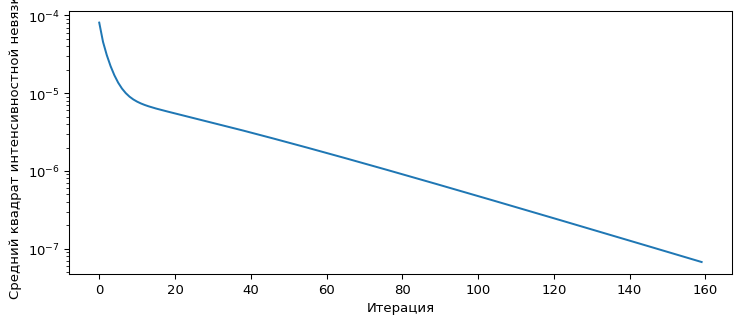

In [4]:
result=cl.psi_unknown(stack,nominal,s['mask'],max_iterations=160)
print('Сошлось:',result['converged'],'итераций:',len(result['history']))
print('Найденные сдвиги:',np.rad2deg(result['shifts'])%360)
print('Ошибка сдвигов, градусы:',np.rad2deg(cl.wrap(result['shifts']-true_shifts)))
print('RMS ошибки фазы, периоды:',np.sqrt(np.mean(cl.wrap(result['phi'][s['mask']]-s['phi'][s['mask']])**2))/cl.TAU)
plt.semilogy(np.maximum(result['history'],1e-25))
plt.xlabel('Итерация'); plt.ylabel('Средний квадрат интенсивностной невязки'); plt.show()
assert np.all(np.diff(result['history'])<1e-9)

**Как читать предыдущий результат.** В этом примере 160 итераций могут закончиться с `converged=False`: это достижение лимита, а не подтверждение решения. Сравните остаточную ошибку сдвигов с известной истиной. Увеличьте лимит до 500 и 1500, постройте ошибку сдвигов наряду с интенсивностной невязкой. Монотонность критерия не гарантирует нужной точности за выбранное число шагов.

## 4. Наклон опорного фронта между кадрами

Вибрация может менять не только общий сдвиг:
$$\delta_n(x,y)=\alpha_n+\beta_n x+\gamma_n y.$$
В курсе β,γ выражены в rad на единицу нормированной координаты. В C++ они могут
быть rad/pixel; чтобы сравнить, учитывайте размер сетки. Плоскость первого кадра
фиксируем нулевой, поэтому оцениваем фазу относительно него, а не абсолютный
наклон невозмущённого интерферометра.

Для $r=I-a-b\cos(\varphi+\delta)$:
$$\partial_\alpha r=b\sin(\varphi+\delta),\quad
\partial_\beta r=x b\sin(\varphi+\delta),\quad
\partial_\gamma r=y b\sin(\varphi+\delta).$$
Это столбцы Якобиана для шага Гаусса—Ньютона. Однако при совместной оценке
нужно также учитывать изменение параметров пикселей.

## 5. Variable projection: отделить линейные неизвестные

Для заданных плоскостей δ линейные a,c,s всё ещё можно найти в каждом пикселе.
Обозначим оптимальные коэффициенты $c^*(\theta)$, где θ содержит только параметры
плоскостей. Внешняя задача минимизирует
$\|r(c^*(\theta),\theta)\|^2$. Так число нелинейных неизвестных уменьшается
до 3(M−1), хотя линейных пиксельных параметров тысячи.

`psi_planes` выполняет внутренние SVD и внешнюю нелинейную минимизацию SciPy.
Производные внешнего критерия оцениваются численно с повторным решением внутренних
задач. Это не транскрипция трёхшагового метода Liu: у него отдельные обновления
фазы и компонент наклона. Общая физическая модель позволяет сравнивать методы,
но совпадение моделей не означает совпадения итерационных алгоритмов.

In [5]:
t=cl.scene(n=32,carrier_x=4,carrier_y=2,bowl=.15)
planes_true=np.column_stack([true_shifts,[0,.12,-.10,.08,-.06],[0,-.08,.11,.06,-.09]])
stack_tilt=np.array([t['a']+t['b']*np.cos(t['phi']+alpha+beta*t['x']+gamma*t['y'])
                     for alpha,beta,gamma in planes_true])
tilt_result=cl.psi_planes(stack_tilt,nominal,t['x'],t['y'],t['mask'])
print('Оптимизация:',tilt_result['optimization'].message)
print('Истинные плоскости [α,β,γ]:\n',planes_true)
print('Найденные плоскости:\n',tilt_result['planes'])
print('Интенсивностная невязка RMS:',np.sqrt(np.mean(tilt_result['residual']**2)))
print('RMS ошибки фазы, периоды:',np.sqrt(np.mean(cl.wrap(tilt_result['phi'][t['mask']]-t['phi'][t['mask']])**2))/cl.TAU)

Оптимизация: `gtol` termination condition is satisfied.
Истинные плоскости [α,β,γ]:
 [[ 0.       0.       0.     ]
 [ 1.309    0.12    -0.08   ]
 [ 2.96706 -0.1      0.11   ]
 [ 4.53786  0.08     0.06   ]
 [ 6.02139 -0.06    -0.09   ]]
Найденные плоскости:
 [[ 0.       0.       0.     ]
 [ 1.309    0.12    -0.08   ]
 [ 2.96706 -0.1      0.11   ]
 [ 4.53786  0.08     0.06   ]
 [ 6.02139 -0.06    -0.09   ]]
Интенсивностная невязка RMS: 3.2708394593143663e-16
RMS ошибки фазы, периоды: 1.37197614053861e-16


## Задания

1. Смените старт на отрицательные номинальные сдвиги. Сравните φ и −φ.
2. Сделайте почти одинаковые сдвиги. Что происходит с внутренним МНК?
3. Добавьте независимое изменение яркости каждого кадра; входит ли оно в выбранную модель?
4. Почему малого изменения δ недостаточно для доказательства правильности карты?

<details><summary>Разбор</summary>

Зеркальные решения могут иметь одинаковую невязку. Почти одинаковые сдвиги делают
матрицы плохо обусловленными. Изменение усиления/фона по кадрам требует расширить
модель и изучить её идентифицируемость. Остановка итераций возможна в локальном
минимуме и при неверной модели. Нужны независимые проверки и критерии качества.
</details>

**В проекте:** `fitFrameShifts`, `solveWithUnknownShifts`, `TiltIterations` в `PhaseShifting.cpp`.
Существующие конспекты и PDF Парпина–Серегина находятся в `notes/Phase-shift`;
сверяйте именно знаки и допущения, а не только номера формул.
**Чтение:** [Liu и др., трёхшаговый метод с наклонами](https://pubmed.ncbi.nlm.nih.gov/24514503/),
[SciPy least_squares](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.least_squares.html).
Далее: [полиномы фронта](10_modal_analysis.ipynb).